# Assignment 3 — Association Rule Mining for Market Basket Analysis
**Data Analytics 1 · MovieLens (ml-latest-small, ~100K ratings)**

Goal: discover movies that are *liked together* and use single-antecedent association rules
`{A} → Y` to recommend movies to a user from the movies already in their watch history.

**Notebook map**
| Section | Assignment part |
|---|---|
| 0. Setup | configuration, data download |
| 1. Data preprocessing | Part A.1 binarisation & filtering, A.2 transactions, A.3 80/20 split |
| 2. Rule mining from scratch | Part B.1 — FP-growth (chosen) + Apriori (for comparison), rule generation |
| 3. Threshold experiments | Part B.2 — minsup × minconf grid, plots, final choice |
| 4. Rule lists | Part C.1 — top-100 by support / confidence, intersection |
| 5. Evaluation logic | Part C.2 — chronological half split, recommender, scoring metric |
| 6. Metrics vs. k | Part C.3 — average precision / recall for k = 1…10 |
| 7. Sample users | Part C.4 — per-user curves and discussion |

**TA clarifications followed**
1. The mining algorithm (FP-growth, and Apriori used as a baseline) is implemented **from scratch** — no `mlxtend` or similar.
2. For Part C.2 every test user's liked movies are **sorted by timestamp**; the older half is the input, the newer half is the ground truth.
3. The metric used to rank the top-k recommendations is stated and justified (Section 5).
4. The report is submitted as a PDF.

## 0. Setup

In [1]:
import os
import time
import json
import itertools
import zipfile
import urllib.request
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:                      # `display` exists inside Jupyter; fall back to print when run as a script
    display
except NameError:
    display = print

# ---- configuration -------------------------------------------------------------------------
TEAM_ID = "2024101035_2024102017"
SEED = 42                                   # one seed drives every random choice -> reproducible
DATA_DIR = os.path.join("data", "ml-latest-small")
OUT_DIR = "outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

LIKE_THRESHOLD = 3.0      # Part A.1: rating >= 3.0 is a "liked" movie
MIN_LIKED = 5             # Part A.1: drop users with fewer than 5 liked movies
TRAIN_FRAC = 0.8          # Part A.3: 80 % train / 20 % test (split by user)
K_MAX = 10                # Part C.3: number of recommendations varied from 1 to 10

# ---- plotting style: thin marks, recessive grid, fixed categorical colour order --------------
C_BLUE, C_ORANGE, C_AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # categorical slots 1-3
BLUE_RAMP = ["#86b6ef", "#6da7ec", "#5598e7", "#3987e5", "#2a78d6", "#1c5cab", "#184f95", "#0d366b"]  # ordinal
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "lines.linewidth": 2, "lines.markersize": 5, "legend.frameon": False,
})

def savefig(fig, name):
    """Save a figure into outputs/figures (used by the report) and show it inline."""
    fig.savefig(os.path.join(FIG_DIR, name))
    plt.show()
    plt.close(fig)

# ---- data: download MovieLens "latest-small" (the 100K-rating version with ratings.csv/movies.csv) if absent
if not os.path.exists(os.path.join(DATA_DIR, "ratings.csv")):
    url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
    os.makedirs("data", exist_ok=True)
    zpath = os.path.join("data", "ml-latest-small.zip")
    urllib.request.urlretrieve(url, zpath)
    with zipfile.ZipFile(zpath) as z:
        z.extractall("data")
print("data directory:", os.path.abspath(DATA_DIR))

data directory: C:\Users\shariff\OneDrive\Desktop\courses\sem5\DA\Assignments\A3\data\ml-latest-small


## 1. Data preprocessing (Part A)
### A.1 Binarisation and filtering
A rating of 3 stars or more is treated as a positive interaction ("liked"); everything below is
dropped, so each (user, movie) pair becomes a binary *liked / not-liked* flag. Users with fewer than
5 liked movies are then removed so that every basket is large enough to be split into an input half
and a ground-truth half later on.

In [2]:
ratings = pd.read_csv(os.path.join(DATA_DIR, "ratings.csv"))
movies = pd.read_csv(os.path.join(DATA_DIR, "movies.csv"))
TITLE = dict(zip(movies.movieId, movies.title))          # movieId -> title, for readable rules

def summary(df, label):
    return {"step": label, "ratings": len(df), "users": df.userId.nunique(), "movies": df.movieId.nunique()}

steps = [summary(ratings, "raw ratings")]

liked = ratings[ratings.rating >= LIKE_THRESHOLD]                       # binarise: keep likes only
steps.append(summary(liked, f"rating >= {LIKE_THRESHOLD}"))

likes_per_user = liked.groupby("userId").size()
active_users = likes_per_user[likes_per_user >= MIN_LIKED].index
liked = liked[liked.userId.isin(active_users)]                          # drop low-activity users
steps.append(summary(liked, f"users with >= {MIN_LIKED} likes"))

prep_table = pd.DataFrame(steps)
display(prep_table)
print(f"users removed by the activity filter: {len(likes_per_user) - len(active_users)}")
print(f"duplicate (user, movie) pairs: {liked.duplicated(['userId', 'movieId']).sum()}")

,step,ratings,users,movies
0,raw ratings,100836,610,9724
1,rating >= 3.0,81763,609,8452
2,users with >= 5 likes,81759,608,8452


users removed by the activity filter: 1
duplicate (user, movie) pairs: 0


### A.2 Transactional dataset
Each user becomes one transaction: the set of unique `movieId`s they liked. We also keep the same
movies as a **chronologically ordered list** (sorted by rating timestamp, ties broken by `movieId`
so the order is deterministic), which Part C.2 needs for its old-half / new-half split.

In [3]:
liked_sorted = liked.sort_values(["userId", "timestamp", "movieId"])
user_history = {                                      # userId -> liked movies, oldest first
    u: list(dict.fromkeys(g.movieId))                 # dict.fromkeys de-duplicates but keeps order
    for u, g in liked_sorted.groupby("userId")
}
transactions = {u: frozenset(seq) for u, seq in user_history.items()}   # userId -> basket (set)

basket_sizes = pd.Series({u: len(t) for u, t in transactions.items()})
print(f"{len(transactions)} transactions; basket size: "
      f"mean {basket_sizes.mean():.1f}, median {basket_sizes.median():.0f}, "
      f"min {basket_sizes.min()}, max {basket_sizes.max()}")
example_user = basket_sizes.index[0]
print(f"example: user {example_user} ->", [TITLE[m] for m in user_history[example_user][:5]], "...")

608 transactions; basket size: mean 134.5, median 62, min 10, max 2117
example: user 1 -> ["She's the One (1996)", 'Star Wars: Episode VI - Return of the Jedi (1983)', 'Bambi (1942)', 'Star Wars: Episode I - The Phantom Menace (1999)', '13th Warrior, The (1999)'] ...


### A.3 80 / 20 split by user
Users (not individual ratings) are shuffled with a fixed seed and split 80 / 20, so a test user's
entire basket is unseen during mining.

train users: 486  |  test users: 122


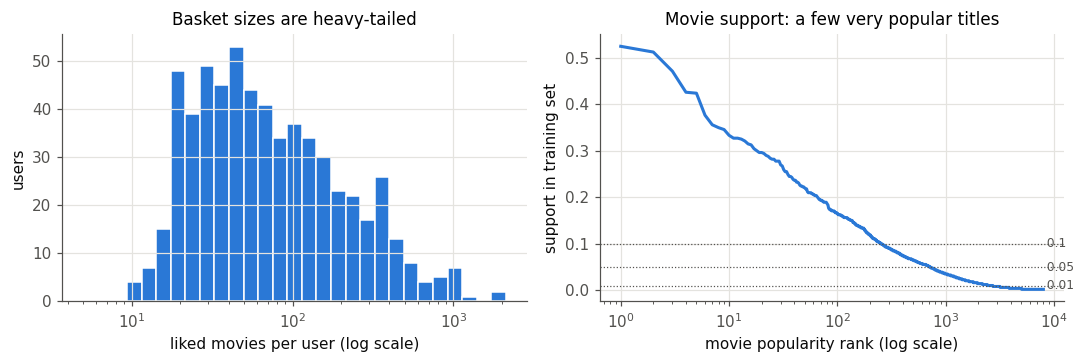

In [4]:
rng = np.random.default_rng(SEED)
all_users = np.array(sorted(transactions))
perm = rng.permutation(all_users)
n_train = int(round(TRAIN_FRAC * len(all_users)))
train_users, test_users = perm[:n_train].tolist(), perm[n_train:].tolist()
train_tx = [transactions[u] for u in train_users]
N_TRAIN = len(train_tx)
print(f"train users: {len(train_users)}  |  test users: {len(test_users)}")

# popularity of each movie in the training set (used for tie-breaking and as a baseline)
train_item_count = defaultdict(int)
for t in train_tx:
    for m in t:
        train_item_count[m] += 1

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
ax = axes[0]
ax.hist(basket_sizes, bins=np.logspace(np.log10(5), np.log10(basket_sizes.max() + 1), 30),
        color=C_BLUE, edgecolor="white", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("liked movies per user (log scale)")
ax.set_ylabel("users")
ax.set_title("Basket sizes are heavy-tailed")
ax = axes[1]
pop = np.sort(np.array(list(train_item_count.values())))[::-1] / N_TRAIN
ax.plot(np.arange(1, len(pop) + 1), pop, color=C_BLUE)
ax.set_xscale("log")
ax.set_xlabel("movie popularity rank (log scale)")
ax.set_ylabel("support in training set")
ax.set_title("Movie support: a few very popular titles")
for s in (0.1, 0.05, 0.01):
    ax.axhline(s, color=INK_2, linewidth=0.8, linestyle=":")
    ax.text(len(pop), s, f" {s}", va="center", fontsize=8, color=INK_2)
fig.tight_layout()
savefig(fig, "A_distributions.png")

## 2. Association rule mining from scratch (Part B.1)
### Choice of algorithm: FP-growth
The baskets here are long and dense (median ≈ 60 liked movies, the largest > 2 000, and the most
popular movie is liked by over half of all users). For Apriori that is the worst case:
* every level re-scans all transactions to count candidates, and
* the number of candidates explodes, because thousands of popular pairs and triples are frequent.

FP-growth compresses the database into a prefix tree once (popular items share prefixes, so the
tree is small for dense data) and grows patterns from conditional trees **without generating candidates**.
Both algorithms are implemented below. Apriori serves as a correctness check (the two must return
identical itemsets) and as a runtime baseline that backs up the choice empirically.

In [5]:
class FPNode:
    """One node of an FP-tree: an item, its count along this path, its parent and children."""
    __slots__ = ("item", "count", "parent", "children")

    def __init__(self, item, parent):
        self.item, self.count, self.parent, self.children = item, 0, parent, {}


def build_fp_tree(weighted_paths, min_count):
    """Build an FP-tree from (items, count) pairs.

    Returns (root, header, freq): `header[item]` lists every node holding `item` (the node-links),
    and `freq[item]` is the item's total count. Infrequent items are dropped before insertion and
    the rest are inserted in descending-frequency order, so common prefixes are shared.
    """
    freq = defaultdict(int)
    for path, cnt in weighted_paths:
        for item in path:
            freq[item] += cnt
    freq = {i: c for i, c in freq.items() if c >= min_count}
    if not freq:
        return None, None, freq
    rank = {i: r for r, i in enumerate(sorted(freq, key=lambda i: (-freq[i], i)))}

    root, header = FPNode(None, None), defaultdict(list)
    for path, cnt in weighted_paths:
        node = root
        for item in sorted((i for i in path if i in rank), key=rank.__getitem__):
            child = node.children.get(item)
            if child is None:                       # new branch -> register it in the header table
                child = FPNode(item, node)
                node.children[item] = child
                header[item].append(child)
            child.count += cnt
            node = child
    return root, header, freq


def fp_growth(transactions, min_count, max_len=None):
    """Mine all frequent itemsets with FP-growth.

    transactions: iterable of item collections; min_count: absolute support threshold.
    Returns {frozenset(itemset): support_count}.
    """
    result = {}

    def mine(weighted_paths, suffix):
        root, header, freq = build_fp_tree(weighted_paths, min_count)
        if root is None:
            return
        # Single-path shortcut: if the (conditional) tree is one chain, every combination of the
        # chain's nodes is frequent, with support = smallest count in the combination.
        node, chain = root, []
        while len(node.children) == 1:
            node = next(iter(node.children.values()))
            chain.append((node.item, node.count))
        if not node.children:
            limit = len(chain) if max_len is None else max_len - len(suffix)
            for r in range(1, limit + 1):
                for combo in itertools.combinations(chain, r):
                    result[frozenset(suffix + tuple(i for i, _ in combo))] = min(c for _, c in combo)
            return
        # General case: for each item (least frequent first) emit suffix+item, then recurse on
        # its conditional pattern base (the prefix paths that lead to that item, weighted by count).
        for item in sorted(freq, key=lambda i: (freq[i], i)):
            new_suffix = suffix + (item,)
            result[frozenset(new_suffix)] = freq[item]
            if max_len is not None and len(new_suffix) >= max_len:
                continue
            cond_base = []
            for n in header[item]:
                path, p = [], n.parent
                while p.item is not None:
                    path.append(p.item)
                    p = p.parent
                if path:
                    cond_base.append((path, n.count))
            if cond_base:
                mine(cond_base, new_suffix)

    mine([(list(t), 1) for t in transactions], ())
    return result


def apriori(transactions, min_count, max_len=None):
    """Classic level-wise Apriori (join + subset-prune + count by scanning the transactions).

    Same interface and output as `fp_growth`; used to cross-check results and compare runtime.
    """
    counts = defaultdict(int)
    for t in transactions:
        for item in t:
            counts[item] += 1
    result = {frozenset([i]): c for i, c in counts.items() if c >= min_count}
    frequent_items = {i for i, c in counts.items() if c >= min_count}
    tx = [frozenset(t) & frequent_items for t in transactions]   # infrequent items can never help

    prev = sorted((i,) for i in frequent_items)                   # L1 as sorted tuples
    k = 2
    while prev and (max_len is None or k <= max_len):
        prev_set = set(prev)
        candidates = []
        for a in range(len(prev)):                 # join: two (k-1)-itemsets sharing a (k-2)-prefix
            for b in range(a + 1, len(prev)):
                if prev[a][:-1] != prev[b][:-1]:
                    break                          # sorted order -> no later tuple shares the prefix
                cand = prev[a] + (prev[b][-1],)
                # prune: every (k-1)-subset must be frequent (the two "parents" already are)
                if all(cand[:m] + cand[m + 1:] in prev_set for m in range(k - 2)):
                    candidates.append(cand)
        cand_sets = [frozenset(c) for c in candidates]
        cand_counts = [0] * len(candidates)
        for t in tx:                               # one database scan per level
            if len(t) < k:
                continue
            for idx, cs in enumerate(cand_sets):
                if cs <= t:
                    cand_counts[idx] += 1
        prev = [c for c, n in zip(candidates, cand_counts) if n >= min_count]
        result.update({frozenset(c): n for c, n in zip(candidates, cand_counts) if n >= min_count})
        k += 1
    return result


def min_count_for(minsup, n):
    """Relative minsup -> absolute count (an itemset is frequent if count >= minsup * n)."""
    return int(np.ceil(minsup * n - 1e-9))

**Correctness and runtime check.** Both miners run on the training set over a range of minsup values.
Their outputs must match exactly. Apriori is stopped once a single run takes longer than 3 minutes.

{'minsup': 0.3, 'itemsets': 23, 'fp_growth_s': 0.015114900000298803, 'apriori_s': 0.013350199999877077, 'identical': True}


{'minsup': 0.25, 'itemsets': 58, 'fp_growth_s': 0.01915240000016638, 'apriori_s': 0.034215799999856245, 'identical': True}


{'minsup': 0.2, 'itemsets': 186, 'fp_growth_s': 0.03748479999967458, 'apriori_s': 0.10123269999985496, 'identical': True}


{'minsup': 0.18, 'itemsets': 350, 'fp_growth_s': 0.0494221999997535, 'apriori_s': 0.16999880000003031, 'identical': True}


{'minsup': 0.15, 'itemsets': 1105, 'fp_growth_s': 0.10397439999997005, 'apriori_s': 0.4500316000003295, 'identical': True}


{'minsup': 0.12, 'itemsets': 4818, 'fp_growth_s': 0.3537399000001642, 'apriori_s': 1.362268800000038, 'identical': True}


{'minsup': 0.1, 'itemsets': 21026, 'fp_growth_s': 0.8765039999998407, 'apriori_s': 4.858519599999909, 'identical': True}


{'minsup': 0.09, 'itemsets': 53987, 'fp_growth_s': 1.445105699999658, 'apriori_s': 8.863158399999975, 'identical': True}


{'minsup': 0.08, 'itemsets': 169506, 'fp_growth_s': 3.504939800000102, 'apriori_s': 22.354943899999853, 'identical': True}


,minsup,itemsets,fp_growth_s,apriori_s,identical
0,0.30,23,0.015115,0.013350,True
1,0.25,58,0.019152,0.034216,True
2,0.20,186,0.037485,0.101233,True
3,0.18,350,0.049422,0.169999,True
4,0.15,1105,0.103974,0.450032,True
5,0.12,4818,0.353740,1.362269,True
6,0.10,21026,0.876504,4.858520,True
7,0.09,53987,1.445106,8.863158,True
8,0.08,169506,3.504940,22.354944,True


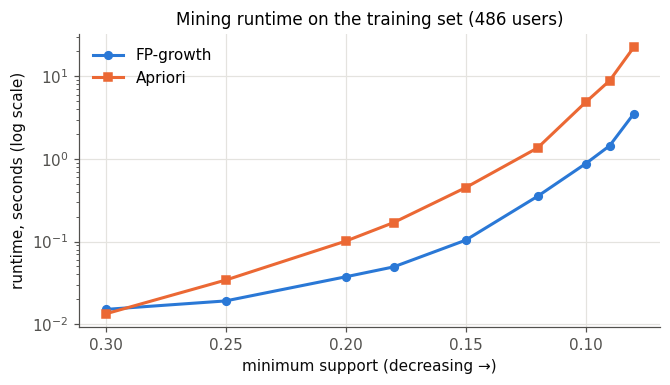

In [6]:
cmp_rows = []
apriori_too_slow = False
for ms in [0.30, 0.25, 0.20, 0.18, 0.15, 0.12, 0.10, 0.09, 0.08]:
    mc = min_count_for(ms, N_TRAIN)
    t0 = time.perf_counter(); fp = fp_growth(train_tx, mc); t_fp = time.perf_counter() - t0
    row = {"minsup": ms, "itemsets": len(fp), "fp_growth_s": t_fp, "apriori_s": np.nan, "identical": None}
    if not apriori_too_slow:
        t0 = time.perf_counter(); ap = apriori(train_tx, mc); t_ap = time.perf_counter() - t0
        row.update(apriori_s=t_ap, identical=(ap == fp))
        apriori_too_slow = t_ap > 180
    cmp_rows.append(row)
    print(row, flush=True)
runtime_cmp = pd.DataFrame(cmp_rows)
display(runtime_cmp)
assert all(v for v in runtime_cmp.identical.dropna()), "FP-growth and Apriori disagree!"

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(runtime_cmp.minsup, runtime_cmp.fp_growth_s, marker="o", color=C_BLUE, label="FP-growth")
ax.plot(runtime_cmp.minsup, runtime_cmp.apriori_s, marker="s", color=C_ORANGE, label="Apriori")
ax.set_yscale("log")
ax.invert_xaxis()
ax.set_xlabel("minimum support (decreasing →)")
ax.set_ylabel("runtime, seconds (log scale)")
ax.set_title("Mining runtime on the training set (486 users)")
ax.legend()
fig.tight_layout()
savefig(fig, "B_runtime_fpgrowth_vs_apriori.png")

### Rule generation: `{A} → Y` with a single-movie antecedent
For every frequent itemset `I` with |I| ≥ 2 and every movie `a ∈ I`, the rule `{a} → I \ {a}` has

* support = sup(I),
* confidence = sup(I) / sup({a}),
* lift = confidence / sup(I \ {a}).

All subsets of a frequent itemset are frequent, so every quantity can be looked up directly in the
mined dictionary and no extra database scan is needed. This enumerates **all** single-antecedent rules
and allows multi-movie consequents, as Part B.1 requires.

In [7]:
def generate_rules(itemsets, n_tx, min_conf, max_itemset_len=None):
    """All rules {a} -> Y (|Y| >= 1) from `itemsets` with confidence >= min_conf, as a DataFrame.
    `max_itemset_len=2` restricts the output to single-movie consequents (used to keep the grid cheap)."""
    rows = []
    for itemset, cnt in itemsets.items():
        if len(itemset) < 2 or (max_itemset_len is not None and len(itemset) > max_itemset_len):
            continue
        for a in itemset:
            conf = cnt / itemsets[frozenset((a,))]
            if conf >= min_conf:
                cons = itemset - {a}
                lift = conf / (itemsets[cons] / n_tx)
                rows.append((a, tuple(sorted(cons)), len(cons), cnt / n_tx, conf, lift))
    return pd.DataFrame(rows, columns=["antecedent", "consequent", "cons_len", "support", "confidence", "lift"])


def rule_confidences(itemsets):
    """Confidence of every single-antecedent rule (no threshold) — cheap way to count rules per minconf."""
    single = {next(iter(s)): c for s, c in itemsets.items() if len(s) == 1}
    return np.fromiter((cnt / single[a] for s, cnt in itemsets.items() if len(s) > 1 for a in s), dtype=float)

## 3. Threshold experiments (Part B.2)
The **minconf** grid covers the suggested range 0.1 – 0.5 and extends to 0.8, to find where minconf starts to matter. For **minsup**, the low end of the suggested
range (0.01 – 0.06) cannot be mined on this data: the number of frequent itemsets grows roughly
3× for every 0.01 decrease below 0.12 (see the plot below). At 0.05 the count is extrapolated to millions of
itemsets and tens of millions of rules, which is far beyond what can be stored or interpreted. The
reason is that a few hundred users each like hundreds of the same popular films, so very long itemsets are
frequent. The grid therefore runs minsup from 0.07 to 0.25.

Two kinds of evidence are collected for each (minsup, minconf):
1. **Size and cost on the full training set**: frequent itemsets, number of rules, runtime, rule quality (mean lift).
2. **Recommendation quality on a validation split**: 20 % of the *training* users are held out, rules are mined
   on the other 80 %, and precision@10, recall@10 and coverage are measured with the exact protocol of Part C.
   The test set is **never** used for tuning.

In [8]:
# ----- helpers shared by validation (here) and testing (Part C) --------------------------------
def split_history(history):
    """Chronological split (TA clarification): older half -> input, newer half -> ground truth."""
    half = len(history) // 2
    return history[:half], history[half:]


def build_score_table(rules_df):
    """antecedent -> {candidate movie: [max_conf, sum_conf, max_lift]} aggregated over all rules
    {a} -> Y with that movie in Y. Precomputing this makes recommendation a few dictionary lookups."""
    table = defaultdict(dict)
    for a, cons, conf, lift in zip(rules_df.antecedent, rules_df.consequent, rules_df.confidence, rules_df.lift):
        row = table[a]
        for y in cons:
            s = row.get(y)
            if s is None:
                row[y] = [conf, conf, lift]
            else:
                s[0] = max(s[0], conf); s[1] += conf; s[2] = max(s[2], lift)
    return table


SCORERS = {"max_conf": 0, "sum_conf": 1, "max_lift": 2}

def recommend(input_items, score_table, k, scorer="max_conf", popularity=train_item_count):
    """Top-k movies for a user whose history is `input_items`.

    Every rule whose antecedent is in the input "fires"; each movie in a fired rule's consequent
    (and not already in the input) becomes a candidate. A candidate's score is aggregated over all rules
    that recommend it (see SCORERS). Ties are broken by training popularity, then by movieId.
    """
    seen, col, scores = set(input_items), SCORERS[scorer], {}
    for a in input_items:
        for y, s in score_table.get(a, {}).items():
            if y in seen:
                continue
            if scorer == "sum_conf":
                scores[y] = scores.get(y, 0.0) + s[col]
            elif s[col] > scores.get(y, -1.0):
                scores[y] = s[col]
    ranked = sorted(scores, key=lambda y: (-scores[y], -popularity.get(y, 0), y))
    return ranked[:k]


def recommend_popular(input_items, k, popularity=train_item_count):
    """Baseline: the k most-liked training movies the user has not already liked."""
    seen = set(input_items)
    return [m for m in POPULAR_ORDER if m not in seen][:k]

POPULAR_ORDER = sorted(train_item_count, key=lambda m: (-train_item_count[m], m))


def evaluate(users, recommender, k_max=K_MAX):
    """Precision@k and recall@k (k = 1..k_max) for every user with more than one liked movie.

    precision@k = hits in the first k recommendations / k
    recall@k    = hits in the first k recommendations / size of the ground-truth half
    Returns one row per user, with columns P1..Pk_max, R1..Rk_max plus bookkeeping fields.
    """
    rows = []
    for u in users:
        hist = user_history[u]
        if len(hist) <= 1:
            continue
        given, truth = split_history(hist)
        truth = set(truth)
        recs = recommender(given, k_max)
        hits = np.cumsum([m in truth for m in recs] + [False] * (k_max - len(recs)))
        row = {"userId": u, "n_liked": len(hist), "n_input": len(given), "n_truth": len(truth), "n_recs": len(recs)}
        row.update({f"P{k}": hits[k - 1] / k for k in range(1, k_max + 1)})
        row.update({f"R{k}": hits[k - 1] / len(truth) for k in range(1, k_max + 1)})
        rows.append(row)
    return pd.DataFrame(rows)

In [9]:
# ----- validation split inside the training users ----------------------------------------------
val_rng = np.random.default_rng(SEED + 1)
val_perm = val_rng.permutation(train_users).tolist()
n_inner = int(round(TRAIN_FRAC * len(val_perm)))
inner_users, val_users = val_perm[:n_inner], val_perm[n_inner:]
inner_tx = [transactions[u] for u in inner_users]
inner_count = defaultdict(int)            # popularity inside inner-train (validation must not see val users)
for t in inner_tx:
    for m in t:
        inner_count[m] += 1
inner_popular = sorted(inner_count, key=lambda m: (-inner_count[m], m))
print(f"inner-train users: {len(inner_users)}  |  validation users: {len(val_users)}")

MINSUP_GRID = [0.25, 0.20, 0.18, 0.15, 0.12, 0.10, 0.09, 0.08, 0.07]
MINCONF_GRID = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

grid_rows = []
for ms in MINSUP_GRID:
    # (1) full training set: size / cost
    t0 = time.perf_counter()
    fi_full = fp_growth(train_tx, min_count_for(ms, N_TRAIN))
    t_mine = time.perf_counter() - t0
    confs = rule_confidences(fi_full)
    # (2) inner-train mining for validation. The grid ranks with max_conf, for which only rules with a
    #     single-movie consequent matter (proved and verified in Section 5), so only those are built here.
    fi_inner = fp_growth(inner_tx, min_count_for(ms, len(inner_tx)))
    rules_inner = generate_rules(fi_inner, len(inner_tx), min(MINCONF_GRID), max_itemset_len=2)
    for mc in MINCONF_GRID:
        table = build_score_table(rules_inner[rules_inner.confidence >= mc])
        ev = evaluate(val_users, lambda g, k: recommend(g, table, k, "max_conf", inner_count))
        grid_rows.append({
            "minsup": ms, "minconf": mc, "itemsets": len(fi_full), "mine_s": t_mine,
            "rules": int((confs >= mc).sum()),
            "val_P10": ev.P10.mean(), "val_R10": ev.R10.mean(),
            "val_cov10": (ev.n_recs >= K_MAX).mean(),   # share of users who receive a full list of 10
        })
    print(f"minsup={ms:.2f}: {len(fi_full):>8} itemsets, {len(confs):>9} rules (no conf filter), "
          f"{t_mine:6.1f}s", flush=True)
    del fi_full, fi_inner, rules_inner, confs

grid = pd.DataFrame(grid_rows)
grid["val_F1_10"] = 2 * grid.val_P10 * grid.val_R10 / (grid.val_P10 + grid.val_R10)
display(grid.round(4))
grid.to_csv(os.path.join(OUT_DIR, "threshold_grid.csv"), index=False)

inner-train users: 389  |  validation users: 97
minsup=0.25:       58 itemsets,        49 rules (no conf filter),    0.0s


minsup=0.20:      186 itemsets,       266 rules (no conf filter),    0.0s


minsup=0.18:      350 itemsets,       617 rules (no conf filter),    0.1s


minsup=0.15:     1105 itemsets,      2496 rules (no conf filter),    0.1s


minsup=0.12:     4818 itemsets,     14155 rules (no conf filter),    0.5s


minsup=0.10:    21026 itemsets,     74986 rules (no conf filter),    0.9s


minsup=0.09:    53987 itemsets,    214683 rules (no conf filter),    1.5s


minsup=0.08:   169506 itemsets,    761543 rules (no conf filter),    3.6s


minsup=0.07:   516843 itemsets,   2588188 rules (no conf filter),    8.3s


,minsup,minconf,itemsets,mine_s,rules,val_P10,val_R10,val_cov10,val_F1_10
0,0.25,0.1,58,0.0257,49,0.0887,0.0215,0.0000,0.0347
1,0.25,0.2,58,0.0257,49,0.0887,0.0215,0.0000,0.0347
2,0.25,0.3,58,0.0257,49,0.0887,0.0215,0.0000,0.0347
3,0.25,0.4,58,0.0257,49,0.0887,0.0215,0.0000,0.0347
4,0.25,0.5,58,0.0257,47,0.0887,0.0215,0.0000,0.0347
...,...,...,...,...,...,...,...,...,...
67,0.07,0.4,516843,8.3006,210870,0.2505,0.0638,0.9381,0.1017
68,0.07,0.5,516843,8.3006,41276,0.2505,0.0638,0.9381,0.1017
69,0.07,0.6,516843,8.3006,9475,0.2485,0.0635,0.8866,0.1012
70,0.07,0.7,516843,8.3006,2734,0.2186,0.0513,0.6495,0.0831


extrapolated #frequent itemsets: {np.float64(0.01): '1.18e+08', np.float64(0.02): '4.62e+07', np.float64(0.03): '1.81e+07', np.float64(0.04): '7.10e+06', np.float64(0.05): '2.78e+06', np.float64(0.06): '1.09e+06'}


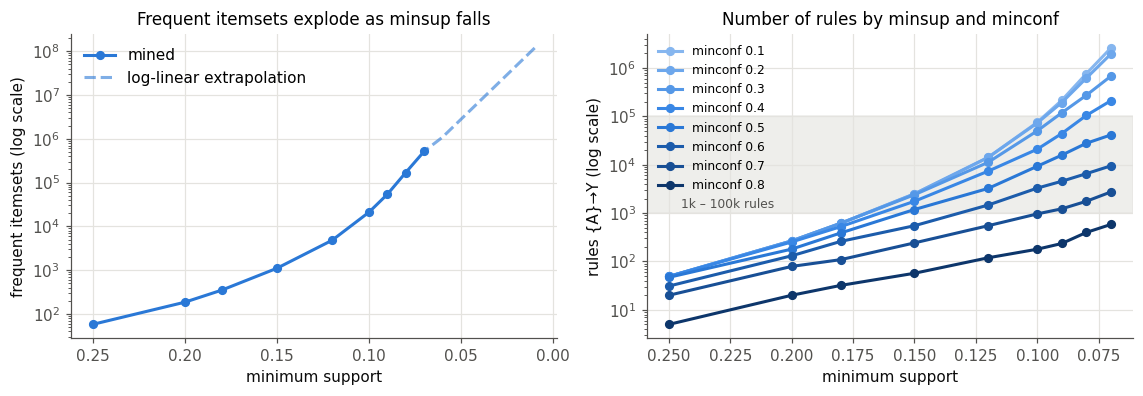

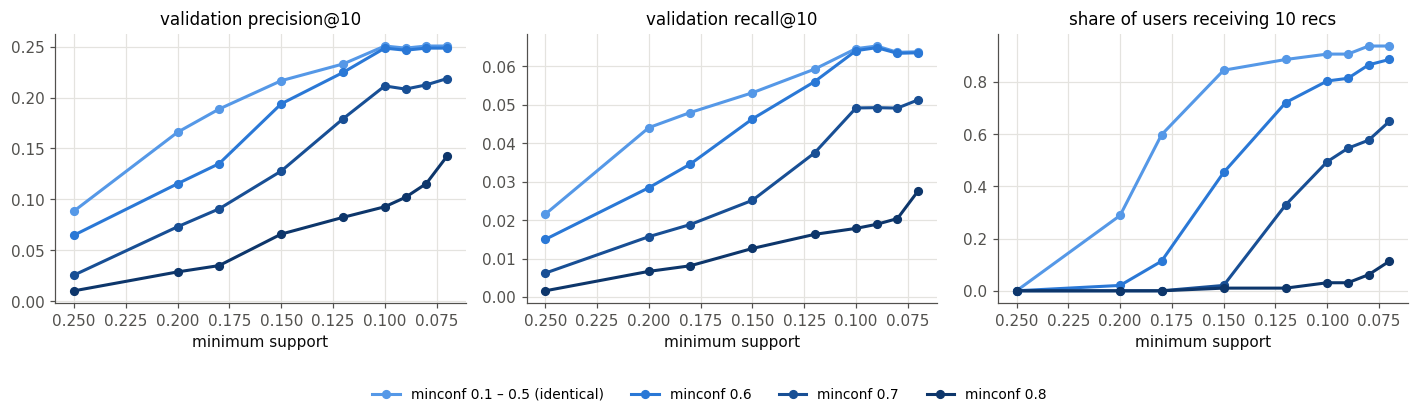

In [10]:
# ----- plots for the threshold study ----------------------------------------------------------
by_ms = grid.drop_duplicates("minsup").sort_values("minsup")

# itemsets vs minsup, with a log-linear fit extrapolated to the low end of the suggested range
fit = np.polyfit(by_ms.minsup[by_ms.minsup <= 0.12], np.log(by_ms.itemsets[by_ms.minsup <= 0.12]), 1)
extrap_ms = np.array([0.01, 0.02, 0.03, 0.04, 0.05, 0.06])
extrap = np.exp(np.polyval(fit, extrap_ms))
print("extrapolated #frequent itemsets:", {m: f"{v:.2e}" for m, v in zip(extrap_ms, extrap)})

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
ax = axes[0]
ax.plot(by_ms.minsup, by_ms.itemsets, marker="o", color=C_BLUE, label="mined")
ax.plot(np.r_[extrap_ms, 0.07], np.r_[extrap, by_ms.itemsets.iloc[0]], linestyle="--",
        color=C_BLUE, alpha=0.6, label="log-linear extrapolation")
ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xlabel("minimum support"); ax.set_ylabel("frequent itemsets (log scale)")
ax.set_title("Frequent itemsets explode as minsup falls")
ax.legend()
ax = axes[1]
for colour, mc in zip(BLUE_RAMP, MINCONF_GRID):
    g = grid[grid.minconf == mc].sort_values("minsup")
    ax.plot(g.minsup, g.rules.clip(lower=1), marker="o", color=colour, label=f"minconf {mc}")
ax.axhspan(1e3, 1e5, color=GRID, alpha=0.6, zorder=0)
ax.text(0.245, 1.3e3, "1k – 100k rules", fontsize=8, color=INK_2)
ax.set_yscale("log"); ax.invert_xaxis()
ax.set_xlabel("minimum support"); ax.set_ylabel("rules {A}→Y (log scale)")
ax.set_title("Number of rules by minsup and minconf")
ax.legend(fontsize=8, ncol=1)
fig.tight_layout()
savefig(fig, "B_itemsets_rules_vs_thresholds.png")

# minconf 0.1-0.5 give identical validation curves (pair rules almost all have conf >= 0.5),
# so they are drawn as one line; the higher values show where minconf starts to bite.
shown = {0.5: ("minconf 0.1 – 0.5 (identical)", BLUE_RAMP[2]), 0.6: ("minconf 0.6", BLUE_RAMP[4]),
         0.7: ("minconf 0.7", BLUE_RAMP[6]), 0.8: ("minconf 0.8", BLUE_RAMP[7])}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True)
for ax, col, label in zip(axes, ["val_P10", "val_R10", "val_cov10"],
                          ["validation precision@10", "validation recall@10", "share of users receiving 10 recs"]):
    for mc, (name, colour) in shown.items():
        g = grid[grid.minconf == mc].sort_values("minsup")
        ax.plot(g.minsup, g[col], marker="o", color=colour, label=name)
    ax.invert_xaxis()
    ax.set_xlabel("minimum support"); ax.set_title(label)
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9,
           bbox_to_anchor=(0.5, -0.06))
fig.tight_layout(rect=(0, 0.06, 1, 1))
savefig(fig, "B_validation_vs_thresholds.png")

### Final choice of (minsup, minconf)
1. **Meaningful number of rules**: only settings with 1 000 – 100 000 rules on the training set are considered.
   Fewer rules leave many users with short or empty recommendation lists. More rules are too many to inspect, and
   below minsup ≈ 0.08 the rule count triples with every 0.01 step with no gain in validation quality.
2. **Quality**: among those, the highest validation F1@10 (harmonic mean of precision@10 and recall@10) wins.
   Settings within 1 % (relative) of the best F1 are treated as ties, because a difference that small is about one
   hit across all 97 validation users.
3. **Coverage guard**: among those near-best settings, only the ones whose coverage (share of validation users who
   get a full list of 10) is within 1 percentage point of the best are kept. A higher minconf must not quietly
   leave users with shorter lists.
4. **Ties** go to the larger minconf and then the larger minsup, i.e. the smaller rule set built from more reliable rules.

In [11]:
ok = grid[(grid.rules >= 1_000) & (grid.rules <= 100_000)].copy()
near_best = ok[ok.val_F1_10 >= 0.99 * ok.val_F1_10.max()]
near_best = near_best[near_best.val_cov10 >= near_best.val_cov10.max() - 0.01]
best = near_best.sort_values(["minconf", "minsup"], ascending=False).iloc[0]
display(near_best.sort_values(["minconf", "minsup"], ascending=False).round(4))
FINAL_MINSUP, FINAL_MINCONF = float(best.minsup), float(best.minconf)
print(f"chosen: minsup = {FINAL_MINSUP}, minconf = {FINAL_MINCONF}")
display(best.to_frame().T)

,minsup,minconf,itemsets,mine_s,rules,val_P10,val_R10,val_cov10,val_F1_10
44,0.10,0.5,21026,0.8826,9281,0.2505,0.0646,0.9072,0.1027
52,0.09,0.5,53987,1.4838,15775,0.2485,0.0653,0.9072,0.1034
43,0.10,0.4,21026,0.8826,20918,0.2505,0.0646,0.9072,0.1027
51,0.09,0.4,53987,1.4838,44144,0.2485,0.0653,0.9072,0.1034
42,0.10,0.3,21026,0.8826,50080,0.2505,0.0646,0.9072,0.1027
41,0.10,0.2,21026,0.8826,72801,0.2505,0.0646,0.9072,0.1027
40,0.10,0.1,21026,0.8826,74986,0.2505,0.0646,0.9072,0.1027


chosen: minsup = 0.1, minconf = 0.5


,minsup,minconf,itemsets,mine_s,rules,val_P10,val_R10,val_cov10,val_F1_10
44,0.1,0.5,21026.0,0.882567,9281.0,0.250515,0.064578,0.907216,0.102685


### Final mining on the full training set

21026 frequent itemsets -> 9281 rules in 0.7s
rules by consequent size: {1: 2893, 2: 3953, 3: 1914, 4: 476, 5: 44, 6: 1}
unique antecedents: 194


,support,confidence,lift
count,9281.000,9281.000,9281.000
mean,0.122,0.587,2.727
std,0.026,0.078,0.793
min,0.101,0.500,1.028
25%,0.105,0.526,2.122
50%,0.113,0.565,2.690
75%,0.128,0.629,3.273
max,0.364,0.982,5.642


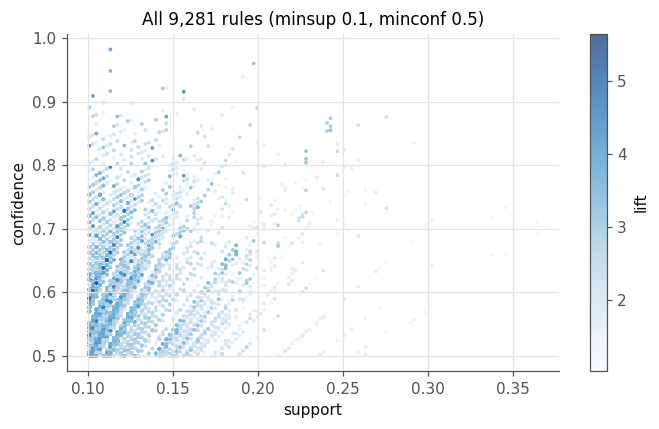

In [12]:
t0 = time.perf_counter()
final_itemsets = fp_growth(train_tx, min_count_for(FINAL_MINSUP, N_TRAIN))
rules = generate_rules(final_itemsets, N_TRAIN, FINAL_MINCONF)
print(f"{len(final_itemsets)} frequent itemsets -> {len(rules)} rules in {time.perf_counter() - t0:.1f}s")
print("rules by consequent size:", rules.cons_len.value_counts().sort_index().to_dict())
print("unique antecedents:", rules.antecedent.nunique())
display(rules[["support", "confidence", "lift"]].describe().round(3))

def fmt_items(items):
    return "{" + ", ".join(f"{TITLE.get(m, m)} [{m}]" for m in items) + "}"

def fmt_rule(r):
    return f"{fmt_items([r.antecedent])} -> {fmt_items(r.consequent)}"

fig, ax = plt.subplots(figsize=(6.4, 4))
sc = ax.scatter(rules.support, rules.confidence, c=rules.lift, cmap="Blues", s=6, alpha=0.7, linewidths=0)
cb = fig.colorbar(sc, ax=ax); cb.set_label("lift")
ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_title(f"All {len(rules):,} rules (minsup {FINAL_MINSUP}, minconf {FINAL_MINCONF})")
fig.tight_layout()
savefig(fig, "B_rules_support_confidence.png")

## 4. Top-100 rule lists (Part C.1)
The two rankings are
* **by support**: support descending, ties broken by confidence and then lift, and
* **by confidence**: confidence descending, ties broken by support and then lift.

A rule is identified by its (antecedent, consequent) pair, which is how the intersection is computed.

In [13]:
order_key = ["antecedent", "consequent"]
top_sup = rules.sort_values(["support", "confidence", "lift"] + order_key,
                            ascending=[False, False, False, True, True]).head(100).reset_index(drop=True)
top_conf = rules.sort_values(["confidence", "support", "lift"] + order_key,
                             ascending=[False, False, False, True, True]).head(100).reset_index(drop=True)

def write_rule_list(df, path, header):
    with open(path, "w", encoding="utf-8") as f:
        f.write(header)
        f.write("rank | rule {antecedent} -> {consequent} | support | confidence | lift\n")
        for i, r in enumerate(df.itertuples(), 1):
            f.write(f"{i} | {fmt_rule(r)} | {r.support:.4f} | {r.confidence:.4f} | {r.lift:.4f}\n")

meta = (f"# minsup = {FINAL_MINSUP}, minconf = {FINAL_MINCONF}; mined with FP-growth (from scratch) on "
        f"{N_TRAIN} training users; {len(rules)} rules in total\n")
write_rule_list(top_conf, os.path.join(OUT_DIR, f"{TEAM_ID}_top100RulesByConf.txt"),
                "# Top 100 association rules by CONFIDENCE (ties: support, then lift)\n" + meta)
write_rule_list(top_sup, os.path.join(OUT_DIR, f"{TEAM_ID}_top100RulesBySup.txt"),
                "# Top 100 association rules by SUPPORT (ties: confidence, then lift)\n" + meta)

both = top_sup.merge(top_conf[order_key].assign(conf_rank=np.arange(1, 101)), on=order_key)
both.insert(0, "sup_rank", [top_sup.index[(top_sup.antecedent == a) & (top_sup.consequent == c)][0] + 1
                            for a, c in zip(both.antecedent, both.consequent)])
both["rule"] = [fmt_rule(r) for r in both.itertuples()]
print(f"rules in BOTH top-100 lists: {len(both)}")
pd.set_option("display.max_colwidth", 120)
display(both[["sup_rank", "conf_rank", "rule", "support", "confidence", "lift"]].round(4))
print("\nTop 5 by support:");    [print(" ", fmt_rule(r), f"s={r.support:.3f} c={r.confidence:.3f}") for r in top_sup.head(5).itertuples()]
print("\nTop 5 by confidence:"); [print(" ", fmt_rule(r), f"s={r.support:.3f} c={r.confidence:.3f}") for r in top_conf.head(5).itertuples()]
print("\ntop-100 by support  — consequent sizes:", top_sup.cons_len.value_counts().sort_index().to_dict(),
      "| support range", (top_sup.support.min().round(3), top_sup.support.max().round(3)),
      "| confidence range", (top_sup.confidence.min().round(3), top_sup.confidence.max().round(3)))
print("top-100 by confidence — consequent sizes:", top_conf.cons_len.value_counts().sort_index().to_dict(),
      "| support range", (top_conf.support.min().round(3), top_conf.support.max().round(3)),
      "| confidence range", (top_conf.confidence.min().round(3), top_conf.confidence.max().round(3)))

rules in BOTH top-100 lists: 10


,sup_rank,conf_rank,rule,support,confidence,lift
0,13,90,{Jurassic Park (1993) [480]} -> {Forrest Gump (1994) [356]},0.2922,0.8353,1.5920
1,17,30,{Star Wars: Episode V - The Empire Strikes Back (1980) [1196]} -> {Star Wars: Episode IV - A New Hope (1977) [260]},0.2757,0.8758,2.3259
2,32,42,{Star Wars: Episode VI - Return of the Jedi (1983) [1210]} -> {Star Wars: Episode IV - A New Hope (1977) [260]},0.2593,0.8630,2.2919
3,48,91,{Apollo 13 (1995) [150]} -> {Forrest Gump (1994) [356]},0.2469,0.8333,1.5882
4,55,31,"{Lord of the Rings: The Two Towers, The (2002) [5952]} -> {Lord of the Rings: The Fellowship of the Ring, The (2001)...",0.2428,0.8741,3.0783
5,56,45,"{Lord of the Rings: The Return of the King, The (2003) [7153]} -> {Lord of the Rings: The Fellowship of the Ring, Th...",0.2428,0.8613,3.0333
6,57,53,"{Lord of the Rings: The Fellowship of the Ring, The (2001) [4993]} -> {Lord of the Rings: The Two Towers, The (2002)...",0.2428,0.8551,3.0783
7,58,54,"{Lord of the Rings: The Fellowship of the Ring, The (2001) [4993]} -> {Lord of the Rings: The Return of the King, Th...",0.2428,0.8551,3.0333
8,60,35,"{Lord of the Rings: The Two Towers, The (2002) [5952]} -> {Lord of the Rings: The Return of the King, The (2003) [71...",0.2407,0.8667,3.0745
9,61,56,"{Lord of the Rings: The Return of the King, The (2003) [7153]} -> {Lord of the Rings: The Two Towers, The (2002) [59...",0.2407,0.8540,3.0745



Top 5 by support:
  {Shawshank Redemption, The (1994) [318]} -> {Forrest Gump (1994) [356]} s=0.364 c=0.711
  {Forrest Gump (1994) [356]} -> {Shawshank Redemption, The (1994) [318]} s=0.364 c=0.694
  {Pulp Fiction (1994) [296]} -> {Forrest Gump (1994) [356]} s=0.346 c=0.734
  {Forrest Gump (1994) [356]} -> {Pulp Fiction (1994) [296]} s=0.346 c=0.659
  {Pulp Fiction (1994) [296]} -> {Shawshank Redemption, The (1994) [318]} s=0.337 c=0.716

Top 5 by confidence:
  {Dark Knight Rises, The (2012) [91529]} -> {Dark Knight, The (2008) [58559]} s=0.113 c=0.982
  {Godfather: Part II, The (1974) [1221]} -> {Godfather, The (1972) [858]} s=0.198 c=0.960
  {Back to the Future Part II (1989) [2011]} -> {Back to the Future (1985) [1270]} s=0.113 c=0.948
  {Mrs. Doubtfire (1993) [500]} -> {Forrest Gump (1994) [356]} s=0.191 c=0.939
  {Sleepless in Seattle (1993) [539]} -> {Forrest Gump (1994) [356]} s=0.146 c=0.922

top-100 by support  — consequent sizes: {1: 83, 2: 17} | support range (np.float64(0.

## 5. Evaluation logic and the ranking metric (Part C.2)
For each test user with more than one liked movie:
1. Their liked movies are **sorted by timestamp** (oldest first). The **first half** (⌊n/2⌋ movies) is the input, i.e. what
   the user has already watched. The **second half** is the ground truth the recommender must predict.
2. Every rule `{a} → Y` with `a` in the input fires. Each movie of `Y` that the user has not already liked is a candidate.
3. Candidates are ranked by a score and the top k are recommended (k = 1…10).

**Which score ranks the top-k?** Three candidate scores are compared on the validation users (never the test set):
* `max_conf`: the highest confidence of any fired rule recommending the movie, i.e. the estimated P(user likes y | user liked a)
  from the strongest piece of evidence.
* `sum_conf`: the sum of confidences over all fired rules (a "voting" score, which rewards movies supported by many watched movies).
* `max_lift`: the highest lift, which favours movies that are unusually tied to the antecedent rather than merely popular.

A popularity baseline (the most-liked unseen training movies) is included for reference.

In [14]:
# Fact used in the report: with max_conf, multi-movie consequents never change the score, because
# conf({a} -> {y}) >= conf({a} -> Y) for every y in Y, and {a} -> {y} is itself a rule above minconf.
pair_rules = rules[rules.cons_len == 1]
pair_max = {(a, c[0]): conf for a, c, conf in zip(pair_rules.antecedent, pair_rules.consequent, pair_rules.confidence)}
assert all(pair_max[(a, y)] >= conf - 1e-12 for a, cons, conf in
           zip(rules.antecedent, rules.consequent, rules.confidence) for y in cons)
print("verified: every multi-item rule is dominated by its single-item sub-rules for max_conf")

# Compare the scores on the validation users with rules mined on the inner-train split
fi_inner = fp_growth(inner_tx, min_count_for(FINAL_MINSUP, len(inner_tx)))
inner_table = build_score_table(generate_rules(fi_inner, len(inner_tx), FINAL_MINCONF))
val_curves = {}
for name in SCORERS:
    ev = evaluate(val_users, lambda g, k, s=name: recommend(g, inner_table, k, s, inner_count))
    val_curves[name] = ev
val_curves["popularity"] = evaluate(val_users, lambda g, k: [m for m in inner_popular if m not in set(g)][:k])

scorer_table = pd.DataFrame({
    name: {"P@1": ev.P1.mean(), "P@5": ev.P5.mean(), "P@10": ev.P10.mean(),
           "R@5": ev.R5.mean(), "R@10": ev.R10.mean()}
    for name, ev in val_curves.items()}).T
display(scorer_table.round(4))

verified: every multi-item rule is dominated by its single-item sub-rules for max_conf


,P@1,P@5,P@10,R@5,R@10
max_conf,0.3505,0.2701,0.2505,0.0350,0.0646
sum_conf,0.3814,0.2722,0.2392,0.0371,0.0628
max_lift,0.3918,0.2907,0.2680,0.0363,0.0701
popularity,0.2887,0.2041,0.1897,0.0248,0.0471


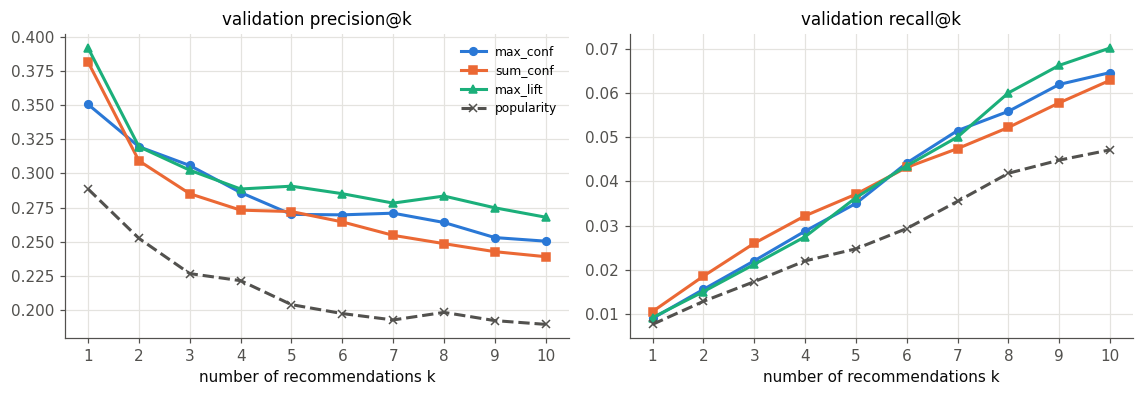

ranking score used for the test set: max_lift


In [15]:
ks = np.arange(1, K_MAX + 1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
styles = {"max_conf": (C_BLUE, "o", "-"), "sum_conf": (C_ORANGE, "s", "-"),
          "max_lift": (C_AQUA, "^", "-"), "popularity": (INK_2, "x", "--")}
for name, ev in val_curves.items():
    colour, marker, ls = styles[name]
    axes[0].plot(ks, [ev[f"P{k}"].mean() for k in ks], marker=marker, linestyle=ls, color=colour, label=name)
    axes[1].plot(ks, [ev[f"R{k}"].mean() for k in ks], marker=marker, linestyle=ls, color=colour, label=name)
for ax, t in zip(axes, ["validation precision@k", "validation recall@k"]):
    ax.set_xlabel("number of recommendations k"); ax.set_title(t); ax.set_xticks(ks)
axes[0].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "C_scorer_comparison_validation.png")

SCORER = scorer_table.drop(index="popularity")["P@10"].idxmax()     # best rule-based score on validation
print("ranking score used for the test set:", SCORER)

## 6. Test-set precision and recall for k = 1…10 (Part C.3)
The final rules (mined on all 486 training users) and the chosen score are applied to the 20 % test users.

,k,precision_ARM,recall_ARM,precision_popularity,recall_popularity
0,1,0.2213,0.0083,0.2131,0.0052
1,2,0.2213,0.0140,0.2090,0.0115
2,3,0.2213,0.0205,0.2022,0.0165
3,4,0.2234,0.0268,0.1926,0.0211
4,5,0.2180,0.0335,0.1836,0.0256
5,6,0.2131,0.0393,0.1817,0.0306
6,7,0.2201,0.0460,0.1862,0.0361
7,8,0.2213,0.0524,0.1855,0.0404
8,9,0.2168,0.0570,0.1812,0.0445
9,10,0.2090,0.0608,0.1754,0.0486


test users evaluated: 122; users with 0 recommendations: 6; with a full list of 10: 94.3%
movies covered by the rule set: 194; mean share of a user's ground truth that is recommendable at all: 32.1%
users with at least one hit in top-10: 69.7%
best achievable average recall@10 (perfect recommender): 0.390


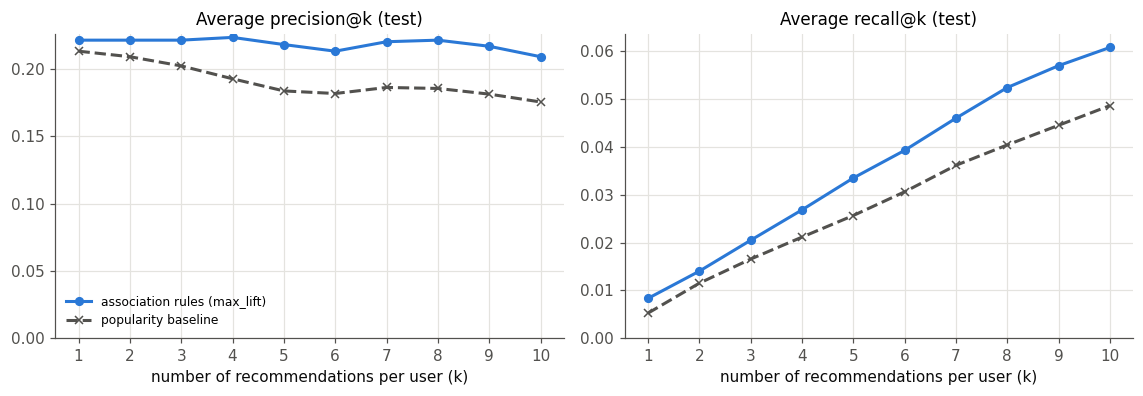

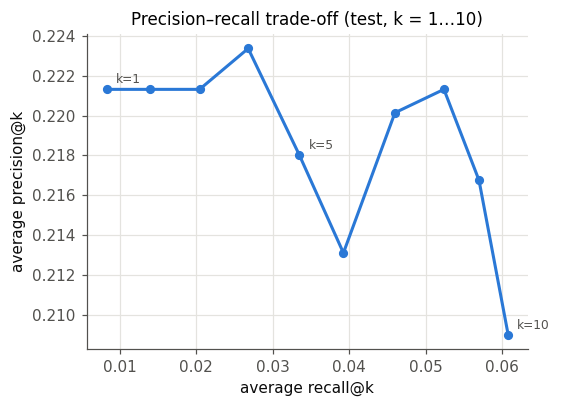

In [16]:
score_table = build_score_table(rules)
test_eval = evaluate(test_users, lambda g, k: recommend(g, score_table, k, SCORER))
pop_eval = evaluate(test_users, recommend_popular)

curve = pd.DataFrame({
    "k": ks,
    "precision_ARM": [test_eval[f"P{k}"].mean() for k in ks],
    "recall_ARM": [test_eval[f"R{k}"].mean() for k in ks],
    "precision_popularity": [pop_eval[f"P{k}"].mean() for k in ks],
    "recall_popularity": [pop_eval[f"R{k}"].mean() for k in ks],
})
display(curve.round(4))
curve.to_csv(os.path.join(OUT_DIR, "test_precision_recall_vs_k.csv"), index=False)

# how much of the ground truth is even reachable by the rules?
rule_items = set(rules.antecedent) | {y for c in rules.consequent for y in c}
reach = np.mean([len(set(split_history(user_history[u])[1]) & rule_items) / len(split_history(user_history[u])[1])
                 for u in test_eval.userId])
print(f"test users evaluated: {len(test_eval)}; users with 0 recommendations: {(test_eval.n_recs == 0).sum()}; "
      f"with a full list of 10: {(test_eval.n_recs >= K_MAX).mean():.1%}")
print(f"movies covered by the rule set: {len(rule_items)}; mean share of a user's ground truth that is "
      f"recommendable at all: {reach:.1%}")
print(f"users with at least one hit in top-10: {(test_eval.P10 > 0).mean():.1%}")
recall_ceiling = np.mean([min(K_MAX, n) / n for n in test_eval.n_truth])   # even a perfect top-10 list
print(f"best achievable average recall@10 (perfect recommender): {recall_ceiling:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
for ax, metric, title in zip(axes, ["precision", "recall"], ["Average precision@k (test)", "Average recall@k (test)"]):
    ax.plot(ks, curve[f"{metric}_ARM"], marker="o", color=C_BLUE, label=f"association rules ({SCORER})")
    ax.plot(ks, curve[f"{metric}_popularity"], marker="x", linestyle="--", color=INK_2, label="popularity baseline")
    ax.set_xlabel("number of recommendations per user (k)"); ax.set_title(title); ax.set_xticks(ks)
    ax.set_ylim(bottom=0)
axes[0].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "C_test_precision_recall_vs_k.png")

# precision–recall trade-off as k grows
fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.plot(curve.recall_ARM, curve.precision_ARM, marker="o", color=C_BLUE)
for k in (1, 5, 10):
    r = curve.iloc[k - 1]
    ax.annotate(f"k={k}", (r.recall_ARM, r.precision_ARM), textcoords="offset points", xytext=(6, 4), fontsize=8, color=INK_2)
ax.set_xlabel("average recall@k"); ax.set_ylabel("average precision@k")
ax.set_title("Precision–recall trade-off (test, k = 1…10)")
fig.tight_layout()
savefig(fig, "C_test_pr_tradeoff.png")

## 7. Sample users (Part C.4)
Four test users are picked by rule (not hand-picked) to show the range of behaviour:
the user with the **best** recall@10, a **typical** user (median precision@10 among users with at least one hit),
a **heavy** user (largest history), and a **light** user (smallest history).

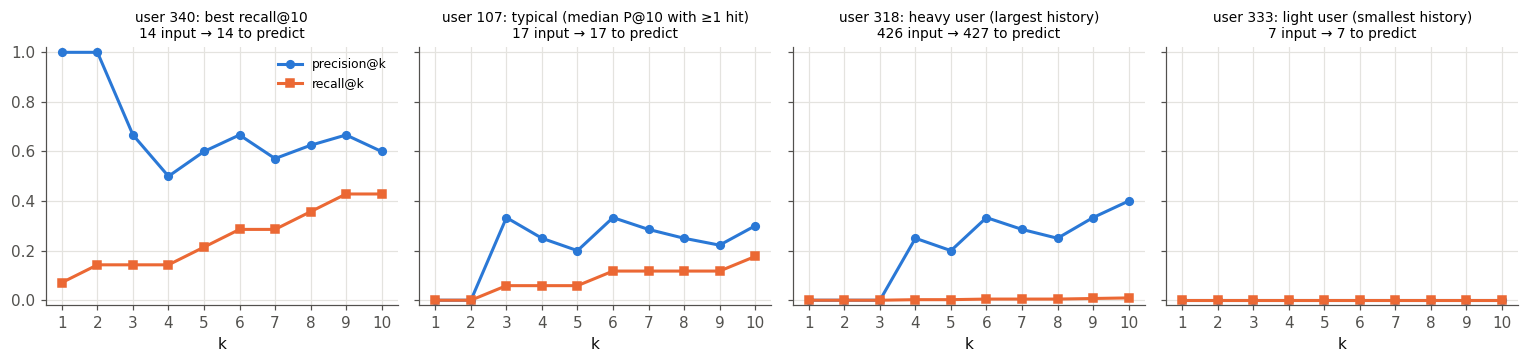

,user,type,liked,P@10,R@10,recommended (✓ = in ground truth),last 3 input movies
0,340,best recall@10,28,0.6,0.428571,"✓ Firm, The (1993); ✓ Crimson Tide (1995); True Lies (1994); Aladdin (1992); ✓ Braveheart (1995); ✓ Terminator 2: Ju...",Stargate (1994); Clear and Present Danger (1994); Forrest Gump (1994)
1,107,typical (median P@10 with ≥1 hit),34,0.3,0.176471,"Fugitive, The (1993); Firm, The (1993); ✓ Crimson Tide (1995); Batman (1989); Aladdin (1992); ✓ Braveheart (1995); T...","Shawshank Redemption, The (1994); Ace Ventura: Pet Detective (1994); Clear and Present Danger (1994)"
2,318,heavy user (largest history),853,0.4,0.009368,"Kill Bill: Vol. 2 (2004); Incredibles, The (2004); Fight Club (1999); ✓ Shawshank Redemption, The (1994); Gladiator ...","League of Extraordinary Gentlemen, The (a.k.a. LXG) (2003); Dogma (1999); Kiss Kiss Bang Bang (2005)"
3,333,light user (smallest history),14,0.0,0.000000,"Godfather, The (1972); Fargo (1996); Forrest Gump (1994); Usual Suspects, The (1995); Godfather: Part II, The (1974)...",Small Time Crooks (2000); Shanghai Noon (2000); Scary Movie (2000)


In [17]:
te = test_eval.set_index("userId")
picks = {}
picks["best recall@10"] = te.sort_values(["R10", "P10", "n_liked"], ascending=[False, False, True]).index[0]
hit_users = te[te.P10 > 0].sort_values(["P10", "n_liked"])
picks["typical (median P@10 with ≥1 hit)"] = hit_users.index[len(hit_users) // 2]
picks["heavy user (largest history)"] = te.n_liked.idxmax()
picks["light user (smallest history)"] = te.sort_values(["n_liked", "userId"]).index[0]

fig, axes = plt.subplots(1, len(picks), figsize=(14, 3.4), sharey=True)
sample_rows = []
for ax, (label, u) in zip(axes, picks.items()):
    r = te.loc[u]
    ax.plot(ks, [r[f"P{k}"] for k in ks], marker="o", color=C_BLUE, label="precision@k")
    ax.plot(ks, [r[f"R{k}"] for k in ks], marker="s", color=C_ORANGE, label="recall@k")
    ax.set_title(f"user {u}: {label}\n{int(r.n_input)} input → {int(r.n_truth)} to predict", fontsize=9)
    ax.set_xlabel("k"); ax.set_xticks(ks); ax.set_ylim(-0.02, 1.02)
    given, truth = split_history(user_history[u])
    recs = recommend(given, score_table, K_MAX, SCORER)
    sample_rows.append({"user": u, "type": label, "liked": int(r.n_liked), "P@10": r.P10, "R@10": r.R10,
                        "recommended (✓ = in ground truth)": "; ".join(("✓ " if m in set(truth) else "") + TITLE[m] for m in recs),
                        "last 3 input movies": "; ".join(TITLE[m] for m in given[-3:])})
axes[0].legend(fontsize=8)
fig.tight_layout()
savefig(fig, "C_sample_users.png")
sample_df = pd.DataFrame(sample_rows)
display(sample_df)

## 8. Save the numbers used in the report

In [18]:
results = {
    "prep": prep_table.to_dict("records"),
    "n_train": N_TRAIN, "n_test": len(test_users), "n_inner": len(inner_users), "n_val": len(val_users),
    "basket": {"mean": float(basket_sizes.mean()), "median": float(basket_sizes.median()),
               "min": int(basket_sizes.min()), "max": int(basket_sizes.max())},
    "runtime_cmp": runtime_cmp.to_dict("records"),
    "extrapolated_itemsets": dict(zip(map(float, extrap_ms), map(float, extrap))),
    "final": {"minsup": FINAL_MINSUP, "minconf": FINAL_MINCONF, "itemsets": len(final_itemsets),
              "rules": len(rules), "antecedents": int(rules.antecedent.nunique()),
              "cons_len": {int(k): int(v) for k, v in rules.cons_len.value_counts().sort_index().items()}},
    "n_both_top100": len(both),
    "both_top100": both[["sup_rank", "conf_rank", "rule", "support", "confidence", "lift"]].to_dict("records"),
    "top_sup_head": [(fmt_rule(r), r.support, r.confidence, r.lift) for r in top_sup.head(10).itertuples()],
    "top_conf_head": [(fmt_rule(r), r.support, r.confidence, r.lift) for r in top_conf.head(10).itertuples()],
    "scorer_table": scorer_table.reset_index().rename(columns={"index": "scorer"}).to_dict("records"),
    "scorer": SCORER,
    "curve": curve.to_dict("records"),
    "test_users_eval": len(test_eval), "zero_rec_users": int((test_eval.n_recs == 0).sum()),
    "full10_share": float((test_eval.n_recs >= K_MAX).mean()), "reachable_truth": float(reach),
    "hit_share": float((test_eval.P10 > 0).mean()), "recall_ceiling": float(recall_ceiling),
    "samples": sample_df.to_dict("records"),
}
with open(os.path.join(OUT_DIR, "results.json"), "w", encoding="utf-8") as f:
    json.dump(results, f, indent=1, default=float, ensure_ascii=False)
print("saved outputs to", os.path.abspath(OUT_DIR))

saved outputs to C:\Users\shariff\OneDrive\Desktop\courses\sem5\DA\Assignments\A3\outputs
